# EDA — 2026 Australian GP Qualifying lap times

Exploratory analysis of `data/session_laptimes.json` (Tracing Insights, Apache-2.0 — see `data/NOTICE.md`).
Field meanings are in `data/DATA_REFERENCE.md` → *LAP TIMES DATA*.

**Contents**
1. Load & clean
2. Structure, nulls, cardinality
3. Coverage: drivers & teams
4. Lap classification (out / in / push / other)
5. Data-quality checks
6. Session timeline & red flags
7. Results & gaps to pole
8. Sectors & theoretical best
9. Track evolution
10. Speed traps
11. Tyres
12. Weather (and why the per-lap fields can't be used)
13. Summary

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

# Works whether the kernel starts in the repo root or in notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data" / "session_laptimes.json"

# Chart styling: recessive axes/grid, thin marks, fixed categorical order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # slots 1-3 (validated all-pairs)
SEG_COLOR = dict(zip(["Q1", "Q2", "Q3"], SERIES))
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 9, "legend.frameon": False,
})

## 1. Load & clean

The file is **columnar**: a dict of equal-length lists, one per field. Missing values are the
**string** `"None"`, so they have to be converted before any numeric work.

In [2]:
raw = json.loads(DATA.read_text())
print(f"{len(raw)} fields x {len({len(v) for v in raw.values()}) and len(next(iter(raw.values())))} rows; "
      f"all lists same length: {len({len(v) for v in raw.values()}) == 1}")

df = pd.DataFrame(raw).replace("None", np.nan)

num_cols = ["time", "s1", "s2", "s3", "sesT", "lST", "s1T", "s2T", "s3T", "pin", "pout",
            "vi1", "vi2", "vfl", "vst", "pos",
            "wT", "wAT", "wH", "wP", "wTT", "wWD", "wWS"]
df[num_cols] = df[num_cols].apply(pd.to_numeric)
for c in ["pb", "del", "fresh", "ff1G", "iacc", "wR"]:
    df[c] = df[c].astype("boolean")          # nullable: pb/del have gaps
df["lSD"] = pd.to_datetime(df["lSD"])
df = df.sort_values(["drv", "lap"]).reset_index(drop=True)
df.head()

43 fields x 355 rows; all lists same length: True


,time,lap,compound,stint,s1,s2,s3,ms1,ms2,ms3,life,pos,status,pb,sesT,drv,dNum,pout,pin,s1T,s2T,s3T,vi1,vi2,vfl,vst,fresh,team,lST,lSD,del,delR,ff1G,iacc,wT,wAT,wH,wP,wR,wTT,wWD,wWS,qs
0,NaN,1,SOFT,1,NaN,20.535,40.833,511111111,11111,1111333311,1,NaN,1,False,873.438,ALB,23,768.671,NaN,NaN,832.687,873.644,240.0,264.0,279.0,115.0,True,Williams,768.671,2026-03-07 05:00:07.383,False,NaN,False,False,893.250,20.5,65.1,1013.5,False,37.5,164,1.9,Q1
1,81.802,2,SOFT,1,28.934,17.771,35.097,111111111,11311,1333113333,2,NaN,1,True,955.240,ALB,23,NaN,NaN,902.372,920.143,955.240,263.0,290.0,300.0,283.0,True,Williams,873.438,2026-03-07 05:01:52.150,False,NaN,False,True,1013.275,20.5,65.8,1013.4,False,37.2,79,4.2,Q1
2,114.904,3,SOFT,1,43.360,24.474,47.070,700000000,00000,0000000000,3,NaN,1,False,1070.144,ALB,23,NaN,NaN,998.600,1023.074,1070.144,139.0,174.0,279.0,244.0,True,Williams,955.240,2026-03-07 05:03:13.952,False,NaN,False,True,1073.291,20.5,65.2,1013.5,False,36.9,79,1.6,Q1
3,82.223,4,SOFT,1,29.214,17.902,35.107,011110100,00000,0000110100,4,NaN,1,False,1152.367,ALB,23,NaN,NaN,1099.358,1117.260,1152.367,263.0,285.0,294.0,284.0,True,Williams,1070.144,2026-03-07 05:05:08.856,False,NaN,False,True,1193.295,20.6,65.4,1013.6,False,36.3,114,2.2,Q1
4,NaN,5,SOFT,1,34.940,21.703,NaN,100000000,00000,0000000555,5,NaN,1,False,1319.851,ALB,23,NaN,1250.304,1187.316,1209.082,NaN,236.0,239.0,NaN,274.0,True,Williams,1152.367,2026-03-07 05:06:31.079,False,NaN,False,False,1313.304,20.5,64.0,1013.5,False,35.7,49,2.6,Q1


## 2. Structure, nulls, cardinality

In [3]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": df.isna().sum(),
    "null_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
    "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
})
overview

,dtype,nulls,null_%,unique,example
time,float64,109,30.7,242,81.802
lap,int64,0,0.0,26,1
compound,str,0,0.0,2,SOFT
stint,int64,0,0.0,8,1
s1,float64,21,5.9,329,28.934
s2,float64,14,3.9,334,20.535
s3,float64,92,25.9,258,40.833
ms1,str,0,0.0,109,511111111
ms2,str,1,0.3,50,11111
ms3,str,1,0.3,135,1111333311


In [4]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
time,246.0,97.348154,78.518,80.856,96.1185,109.94375,149.731,16.582526
lap,355.0,10.529577,1.0,5.0,10.0,15.5,26.0,6.406309
stint,355.0,3.0,1.0,1.0,3.0,4.0,8.0,1.824194
s1,334.0,37.38818,27.498,28.80325,34.232,40.83675,94.733,11.369705
s2,341.0,20.311396,17.284,17.819,20.286,21.41,28.574,2.283835
s3,263.0,40.054342,33.736,34.6835,39.504,43.5475,59.806,5.622871
life,355.0,3.171831,1.0,2.0,3.0,4.0,11.0,1.922597
pos,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sesT,355.0,2930.535141,866.869,1969.184,2961.919,3652.8165,5659.934,1391.089609
pout,99.0,2861.824121,764.437,1915.076,2860.948,3904.5305,5388.536,1466.674689


In [5]:
for c in ["compound", "qs", "status", "delR"]:
    print(df[c].value_counts(dropna=False).to_string(), "\n")

compound
SOFT      339
MEDIUM     16 

qs
Q1    171
Q2    121
Q3     63 

status
1      301
12      26
125     19
152      9 

delR
NaN                               352
TRACK LIMITS AT TURN 7 LAP 3        1
TRACK LIMITS AT TURN 9 LAP 12       1
TRACK LIMITS AT TURN 9 LAP 10       1 



Notes
- `pos` is entirely null — expected: the reference says position is `None` for qualifying.
- `status` is a **sequence** of track-status codes during the lap, so `125` (clear → yellow → red) and
  `152` (clear → red → yellow) are different. Any lap containing `5` was hit by a red flag.
- Only 3 deleted laps; `delR` is populated only on those.

## 3. Coverage: drivers & teams

In [6]:
coverage = (df.groupby(["team", "drv", "dNum"])
              .agg(laps=("lap", "size"), timed_laps=("time", "count"),
                   stints=("stint", "max"), segments=("qs", lambda s: ",".join(sorted(s.unique()))))
              .reset_index())
coverage

,team,drv,dNum,laps,timed_laps,stints,segments
0,Alpine,COL,43,18,14,4,"Q1,Q2"
1,Alpine,GAS,10,18,14,4,"Q1,Q2"
2,Aston Martin,ALO,14,10,8,2,Q1
3,Audi,BOR,5,14,12,3,"Q1,Q2"
4,Audi,HUL,27,18,13,4,"Q1,Q2"
5,Cadillac,BOT,77,8,5,3,Q1
6,Cadillac,PER,11,7,4,3,Q1
7,Ferrari,HAM,44,24,18,7,"Q1,Q2,Q3"
8,Ferrari,LEC,16,24,16,7,"Q1,Q2,Q3"
9,Haas F1 Team,BEA,87,18,13,4,"Q1,Q2"


In [7]:
per_team = df.groupby("team").drv.nunique()
print(f"{df.drv.nunique()} drivers across {df.team.nunique()} teams")
print("Teams with fewer than 2 drivers:", per_team[per_team < 2].to_dict())

20 drivers across 11 teams
Teams with fewer than 2 drivers: {'Aston Martin': 1, 'Williams': 1}


The 2026 grid has 22 cars (11 teams × 2), but only **20 drivers** appear. Aston Martin and Williams
each have a single driver, so Stroll and Sainz are absent from the file entirely. Verstappen has just 2 laps.

## 4. Lap classification

`time` is populated on **out-laps** too (including pit-lane time), so a naive `min(time)` or mean is
misleading. Classify each lap first:

| type | rule |
|---|---|
| `red_flag` | `status` contains `5` (checked first: these laps usually end in the pits) |
| `out` | has `pout` (left the pits this lap) |
| `in` | has `pin` (entered the pits this lap) |
| `push` | timed, not out/in, not deleted, within 107% of the session's best |
| `other` | everything else (cool-down, prep, aborted laps) |

In [8]:
best_overall = df.loc[df["del"] != True, "time"].min()

def lap_type(r):
    if "5" in str(r.status): return "red_flag"
    if pd.notna(r.pout): return "out"
    if pd.notna(r.pin): return "in"
    if pd.notna(r.time) and r["del"] != True and r.time < 1.07 * best_overall: return "push"
    return "other"

df["lap_type"] = df.apply(lap_type, axis=1)
push = df[df.lap_type == "push"].copy()
print(df.lap_type.value_counts().to_string())
print(f"\nNaive min(time) per driver would make VER's best lap "
      f"{df[df.drv == 'VER'].time.min():.3f}s — that's an out-lap.")

lap_type
push        102
out          95
other        65
in           65
red_flag     28

Naive min(time) per driver would make VER's best lap 102.025s — that's an out-lap.


## 5. Data-quality checks

In [9]:
checks = {}

# 5a. Sectors sum to lap time
t = df.dropna(subset=["time", "s1", "s2", "s3"])
checks["max |s1+s2+s3 - time|"] = (t.s1 + t.s2 + t.s3 - t.time).abs().max()

# 5b. Lap duration vs time — differs only on out-laps (time excludes part of the pit lane)
dur_gap = (df.sesT - df.lST - df.time).abs()
mism = df[dur_gap > 0.01]
checks["laps where sesT-lST != time"] = len(mism)
checks["... of which out-laps"] = int(mism.pout.notna().sum())
checks["max duration gap (s)"] = dur_gap.max()

# 5c. pb matches each driver's fastest non-deleted lap
fastest = df[df["del"] != True].groupby("drv").time.min()
pb_best = df[df.pb == True].groupby("drv").time.min()
checks["drivers where pb != fastest valid lap"] = int((fastest.drop("VER") != pb_best).sum())

# 5d. FastF1-generated laps
checks["FastF1-generated laps (ff1G)"] = int(df.ff1G.sum())

pd.Series({k: round(v, 3) for k, v in checks.items()}, name="value", dtype=object).to_frame()

,value
max |s1+s2+s3 - time|,0.0
laps where sesT-lST != time,35
... of which out-laps,35
max duration gap (s),22.256
drivers where pb != fastest valid lap,0
FastF1-generated laps (ff1G),2


**Deleted laps: the reason text is off by one.** The `del` flag sits on the correct row, but the lap
number in `delR` is always `lap + 1`.

In [10]:
d = df[df["del"] == True][["drv", "lap", "qs", "time", "delR"]].copy()
d["lap_in_delR"] = d.delR.str.extract(r"LAP (\d+)").astype(int)
d["offset"] = d.lap_in_delR - d.lap
d

,drv,lap,qs,time,delR,lap_in_delR,offset
88,COL,2,Q1,83.393,TRACK LIMITS AT TURN 7 LAP 3,3,1
152,HAM,11,Q2,96.101,TRACK LIMITS AT TURN 9 LAP 12,12,1
339,RUS,9,Q2,139.248,TRACK LIMITS AT TURN 9 LAP 10,10,1


**Sector values carried over from the previous lap** (likely feed artefacts on aborted laps):

In [11]:
carry = []
for s in ["s1", "s2", "s3"]:
    prev = df.groupby("drv")[s].shift(1)
    hit = df[(df[s] == prev) & df[s].notna()]
    carry += [dict(drv=r.drv, lap=r.lap, sector=s, value=getattr(r, s), lap_type=r.lap_type) for r in hit.itertuples()]
pd.DataFrame(carry)

,drv,lap,sector,value,lap_type
0,VER,2,s1,41.429,red_flag
1,BOR,14,s3,34.531,in


**Segment boundaries overlap slightly**: `qs` labels come from the timing feed, so the first Q3
out-laps start before the last Q2 laps finish.

In [12]:
df.groupby("qs").agg(first_lap_start=("lST", "min"), last_lap_end=("sesT", "max"), laps=("lap", "size"))

,first_lap_start,last_lap_end,laps
qs,,,
Q1,764.437,2963.364,171
Q2,2753.628,4458.213,121
Q3,4305.332,5659.934,63


## 6. Session timeline & red flags

In [13]:
red = df[df.status.str.contains("5")]
print(red.groupby("qs").agg(laps_hit=("lap", "size"), drivers=("drv", "nunique"),
                            first_pit_in=("pin", "min"), last_pit_in=("pin", "max")).to_string())

    laps_hit  drivers  first_pit_in  last_pit_in
qs                                              
Q1        19       19      1259.038     1677.674
Q3         9        9      4509.807     4612.423


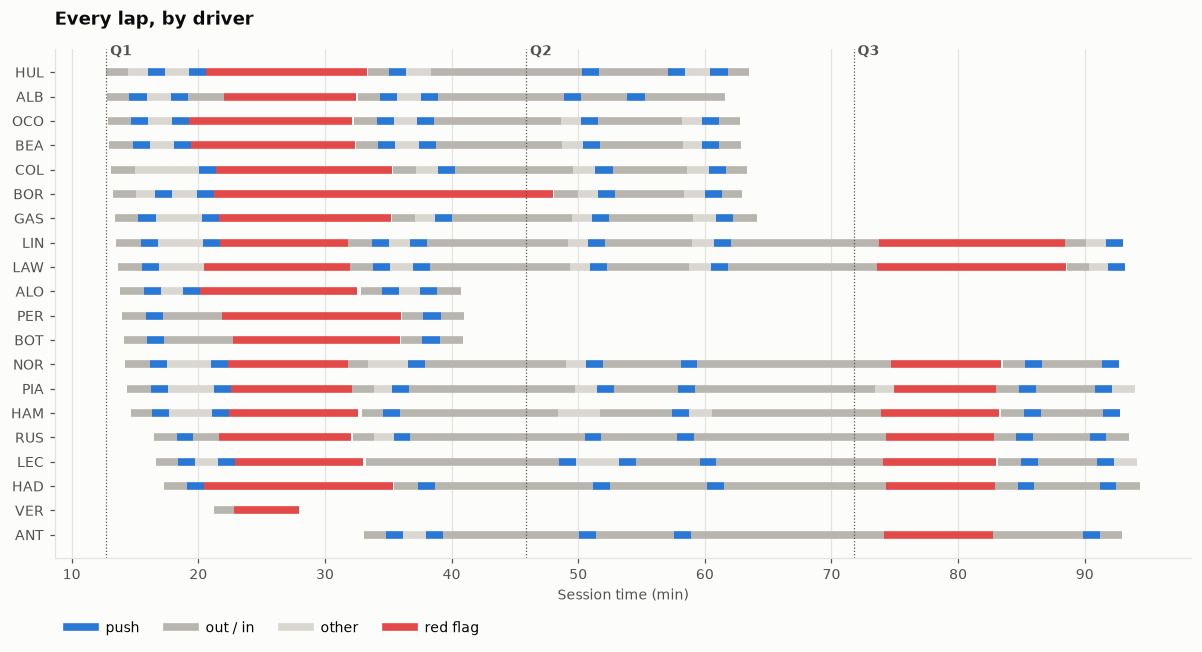

In [14]:
TYPE_COLOR = {"push": SERIES[0], "out": "#b7b5ae", "in": "#b7b5ae", "other": "#d9d7d0", "red_flag": "#e34948"}
order = (df.groupby("drv").lST.min().sort_values(ascending=False).index)  # first out on top
ypos = {d: i for i, d in enumerate(order)}

fig, ax = plt.subplots(figsize=(11, 6))
for r in df.itertuples():
    ax.plot([r.lST / 60, r.sesT / 60], [ypos[r.drv]] * 2, color=TYPE_COLOR[r.lap_type],
            lw=5, solid_capstyle="butt")
for q, g in df.groupby("qs"):
    ax.axvline(g.lST.min() / 60, color=INK2, lw=0.8, ls=":")
    ax.text(g.lST.min() / 60 + 0.3, len(order) - 0.3, q, color=INK2, fontweight="bold")
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Session time (min)")
ax.set_title("Every lap, by driver", pad=16)
handles = [plt.Line2D([], [], color=c, lw=5, label=k) for k, c in
           [("push", SERIES[0]), ("out / in", "#b7b5ae"), ("other", "#d9d7d0"), ("red flag", "#e34948")]]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.1), ncols=4)
ax.grid(axis="y", visible=False)
plt.tight_layout()

- **Q1 red flag** (~23 min in): every car on track was caught. Verstappen's lap 2 stops after three
  mini-sectors (`ms1 = 134777777`), he pits and never returns — consistent with him causing the
  stoppage, though the data doesn't record a cause.
- **Q3 red flag** came during the first runs, so the 9 cars that set Q3 times had their first
  attempt wiped out.

In [15]:
df[df.drv == "VER"][["lap", "qs", "time", "s1", "s2", "s3", "lST", "sesT", "pout", "pin", "status", "ms1"]]

,lap,qs,time,s1,s2,s3,lST,sesT,pout,pin,status,ms1
353,1,Q1,102.025,41.429,19.065,41.531,1273.117,1371.416,1273.117,NaN,1,511111111
354,2,Q1,NaN,41.429,NaN,NaN,1371.416,1677.674,NaN,1677.674,125,134777777


## 7. Results & gaps to pole

In [16]:
seg_best = push.groupby(["drv", "qs"]).time.min().unstack()
res = seg_best.join(df.groupby("drv").team.first())
for q in ["Q1", "Q2", "Q3"]:
    res[f"{q}_rank"] = res[q].rank()

def sort_key(r):
    for i, q in enumerate(["Q3", "Q2", "Q1"]):
        if pd.notna(r[q]): return (i, r[q])
    return (3, np.inf)

res = res.loc[sorted(res.index, key=lambda d: sort_key(res.loc[d]))]
res.insert(0, "P", range(1, len(res) + 1))
res["best"] = res[["Q1", "Q2", "Q3"]].min(axis=1)
res["gap_to_pole"] = res.best - res.best.min()
res[["P", "team", "Q1", "Q2", "Q3", "best", "gap_to_pole"]].round(3)

,P,team,Q1,Q2,Q3,best,gap_to_pole
drv,,,,,,,
RUS,1,Mercedes,79.507,78.934,78.518,78.518,0.000
ANT,2,Mercedes,80.120,79.435,78.811,78.811,0.293
HAD,3,Red Bull Racing,80.023,79.653,79.303,79.303,0.785
LEC,4,Ferrari,80.226,79.357,79.327,79.327,0.809
PIA,5,McLaren,79.664,79.525,79.380,79.380,0.862
NOR,6,McLaren,80.010,79.882,79.475,79.475,0.957
HAM,7,Ferrari,79.811,79.921,79.478,79.478,0.960
LAW,8,Racing Bulls,80.491,80.144,79.994,79.994,1.476
LIN,9,Racing Bulls,80.409,79.971,81.247,79.971,1.453


In [17]:
q2_top10 = res.Q2.dropna().nsmallest(10).index
print("Top 10 in Q2 without a Q3 lap:", sorted(set(q2_top10) - set(res.Q3.dropna().index)))

Top 10 in Q2 without a Q3 lap: ['BOR']


Bortoleto was 10th in Q2 but has no Q3 laps (his last pit-in is during Q2) — either he didn't run,
or the laps are missing. Verstappen has no push lap at all.

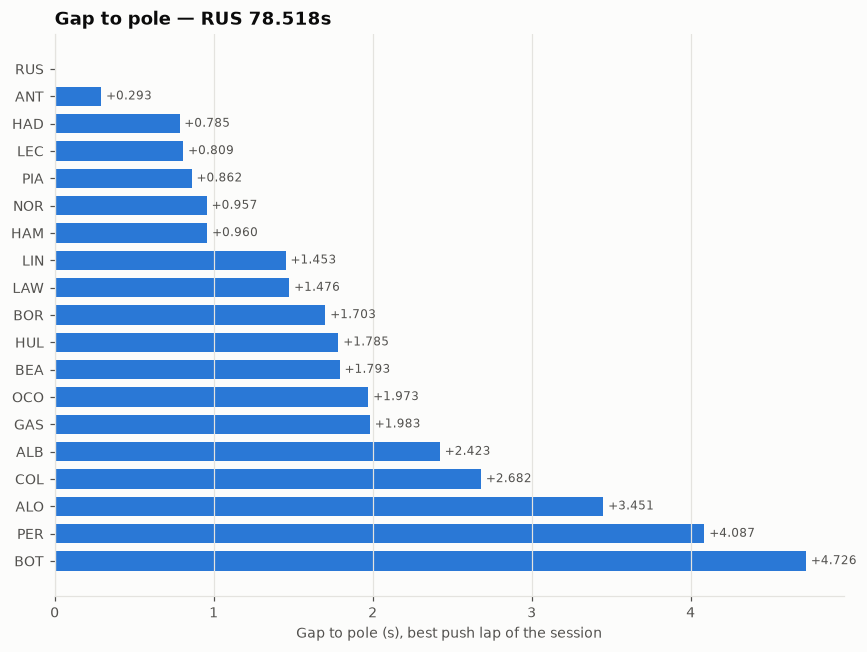

In [18]:
g = res.dropna(subset=["best"]).sort_values("gap_to_pole")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(g.index, g.gap_to_pole, color=SERIES[0], height=0.7)
ax.invert_yaxis()
for i, (d, v) in enumerate(g.gap_to_pole.items()):
    if v > 0:
        ax.text(v + 0.03, i, f"+{v:.3f}", va="center", color=INK2, fontsize=8)
ax.set_xlabel("Gap to pole (s), best push lap of the session")
ax.set_title(f"Gap to pole — {g.index[0]} {g.best.iloc[0]:.3f}s")
ax.grid(axis="y", visible=False)
plt.tight_layout()

## 8. Sectors & theoretical best

In [19]:
sec = push.groupby("drv")[["s1", "s2", "s3"]].min()
sec["theoretical"] = sec.sum(axis=1)
sec["actual"] = push.groupby("drv").time.min()
sec["left_on_table"] = (sec.actual - sec.theoretical).clip(lower=0)
sec.sort_values("theoretical").round(3)

,s1,s2,s3,theoretical,actual,left_on_table
drv,,,,,,
RUS,27.498,17.284,33.736,78.518,78.518,0.000
ANT,27.556,17.440,33.815,78.811,78.811,0.000
HAD,27.747,17.453,34.036,79.236,79.303,0.067
LEC,27.679,17.505,34.061,79.245,79.327,0.082
PIA,27.737,17.537,33.988,79.262,79.380,0.118
NOR,27.754,17.568,34.077,79.399,79.475,0.076
HAM,27.756,17.570,34.152,79.478,79.478,0.000
LIN,28.023,17.312,34.418,79.753,79.971,0.218
LAW,28.198,17.360,34.352,79.910,79.994,0.084


In [20]:
session_best = push[["s1", "s2", "s3"]].min()
print("Session-best sectors:", session_best.to_dict(), "→ ultimate lap", round(session_best.sum(), 3))
print(push.loc[push[["s1", "s2", "s3"]].idxmin(), ["drv", "lap", "qs"]].drop_duplicates().to_string())

Session-best sectors: {'s1': 27.498, 's2': 17.284, 's3': 33.736} → ultimate lap 78.518
     drv  lap  qs
351  RUS   21  Q3


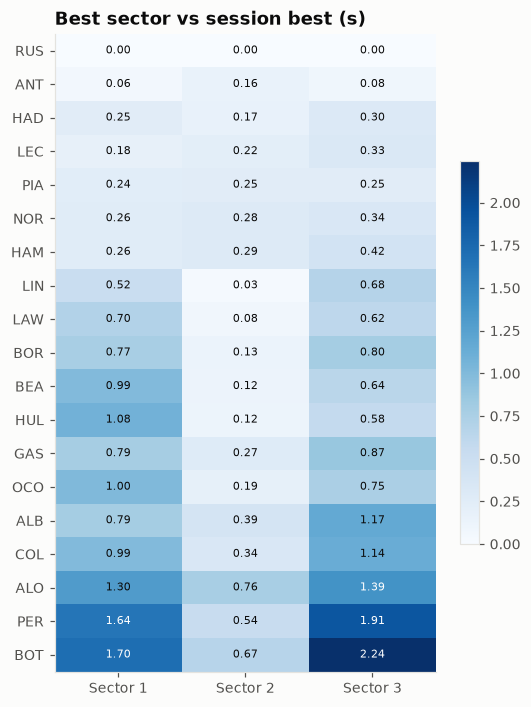

In [21]:
gap = (sec[["s1", "s2", "s3"]] - session_best).loc[sec.sort_values("theoretical").index]
fig, ax = plt.subplots(figsize=(5, 6.5))
im = ax.imshow(gap.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(3), ["Sector 1", "Sector 2", "Sector 3"])
ax.set_yticks(range(len(gap)), gap.index)
for (i, j), v in np.ndenumerate(gap.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
            color="white" if v > gap.values.max() * 0.6 else INK)
ax.grid(False)
ax.set_title("Best sector vs session best (s)")
fig.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout()

## 9. Track evolution

,count,mean,std,min,25%,50%,75%,max
qs,,,,,,,,
Q1,54.0,81.158,0.980,79.507,80.446,81.070,81.471,83.641
Q2,33.0,80.344,0.869,78.934,79.706,80.221,80.826,82.860
Q3,15.0,79.656,0.694,78.518,79.315,79.478,80.119,81.247


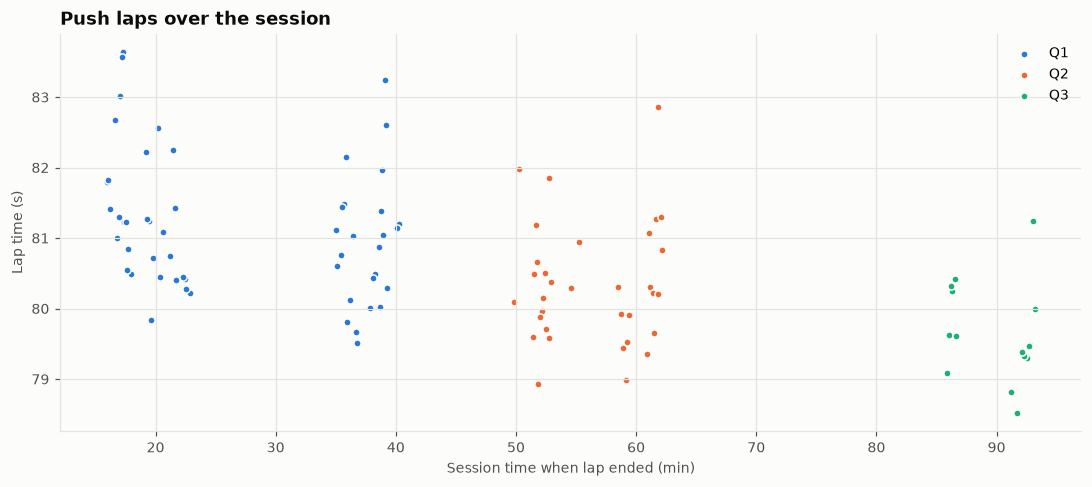

In [22]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for q, g in push.groupby("qs"):
    ax.scatter(g.sesT / 60, g.time, s=22, color=SEG_COLOR[q], label=q,
               edgecolor="#fcfcfb", linewidth=1)
ax.set_xlabel("Session time when lap ended (min)")
ax.set_ylabel("Lap time (s)")
ax.set_title("Push laps over the session")
ax.legend(loc="upper right")
plt.tight_layout()

push.groupby("qs").time.describe().round(3)

The fastest lap drops ~0.6 s from Q1 to Q2 and ~0.4 s from Q2 to Q3. That mixes track evolution
with a shrinking, faster field, so it isn't a pure rubbering-in measure.

## 10. Speed traps

In [23]:
traps = df.groupby("team")[["vi1", "vi2", "vfl", "vst"]].max().sort_values("vst", ascending=False)
traps

,vi1,vi2,vfl,vst
team,,,,
Racing Bulls,284.0,301.0,318.0,315.0
Audi,260.0,291.0,304.0,311.0
Ferrari,277.0,303.0,307.0,309.0
Cadillac,264.0,308.0,304.0,307.0
Red Bull Racing,288.0,295.0,310.0,305.0
Alpine,283.0,292.0,302.0,302.0
Haas F1 Team,282.0,305.0,309.0,300.0
McLaren,271.0,286.0,306.0,297.0
Mercedes,279.0,287.0,301.0,297.0


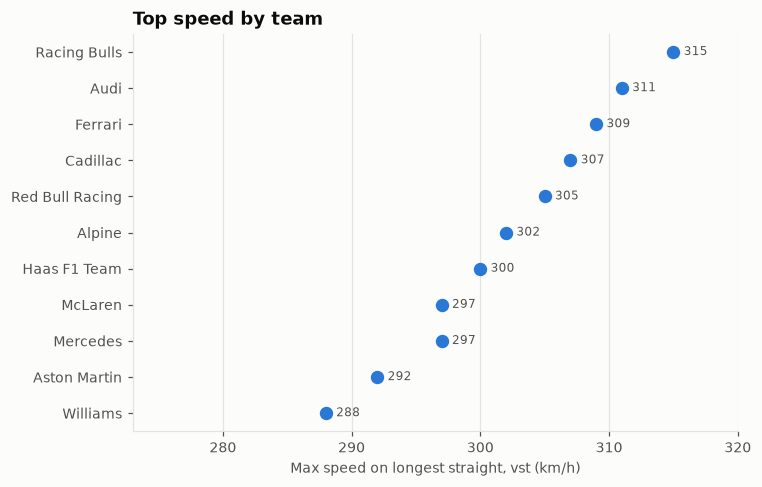

In [24]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(traps.vst, traps.index, s=60, color=SERIES[0], zorder=3)
ax.invert_yaxis()
ax.set_xlim(traps.vst.min() - 15, traps.vst.max() + 5)
for i, v in enumerate(traps.vst):
    ax.text(v + 0.8, i, f"{v:.0f}", va="center", color=INK2, fontsize=8)
ax.set_xlabel("Max speed on longest straight, vst (km/h)")
ax.set_title("Top speed by team")
ax.grid(axis="y", visible=False)
plt.tight_layout()

Mercedes took the front row with only the joint-8th top speed, so their pace came from the corners.

## 11. Tyres

In [25]:
print(pd.crosstab(df.compound, df.qs, margins=True).to_string(), "\n")
print(df[df.compound == "MEDIUM"].groupby("drv").agg(laps=("lap", "size"), last_lap=("lap", "max")).to_string())

qs         Q1   Q2  Q3  All
compound                   
MEDIUM     16    0   0   16
SOFT      155  121  63  339
All       171  121  63  355 

     laps  last_lap
drv                
HAM     9         9
LEC     7         7


In [26]:
pd.crosstab(push.qs, push.fresh, values=push.time, aggfunc="mean").round(3)

fresh,False,True
qs,,
Q1,80.221,81.298
Q2,80.096,80.410
Q3,79.884,79.504


Laps on used tyres look faster overall, but within each segment the comparison is mixed. Used sets
mostly run later in a session when the track is quicker, so the overall difference isn't a tyre effect.

## 12. Weather

The per-lap weather fields (`wT`, `wAT`, `wTT`, …) are supposed to be the weather sample nearest each lap.
In this file they're **matched by lap number instead of session time**: every driver's lap *N* carries
identical weather, however far apart those laps actually were.

In [27]:
print("Distinct wT values per lap number (max):", df.groupby("lap").wT.nunique().max())
gap = (df.wT - df.lST).abs()
print(f"|weather time - lap start|: median {gap.median():.0f}s, max {gap.max():.0f}s")
df[df.lap == 5][["drv", "lST", "wT", "wTT", "wAT"]].head(6)

Distinct wT values per lap number (max): 1
|weather time - lap start|: median 110s, max 4695s


,drv,lST,wT,wTT,wAT
4,ALB,1152.367,1313.304,35.7,20.5
23,ALO,1210.388,1313.304,35.7,20.5
33,ANT,2357.917,1313.304,35.7,20.5
51,BEA,1165.506,1313.304,35.7,20.5
69,BOR,1193.066,1313.304,35.7,20.5
83,BOT,1364.317,1313.304,35.7,20.5


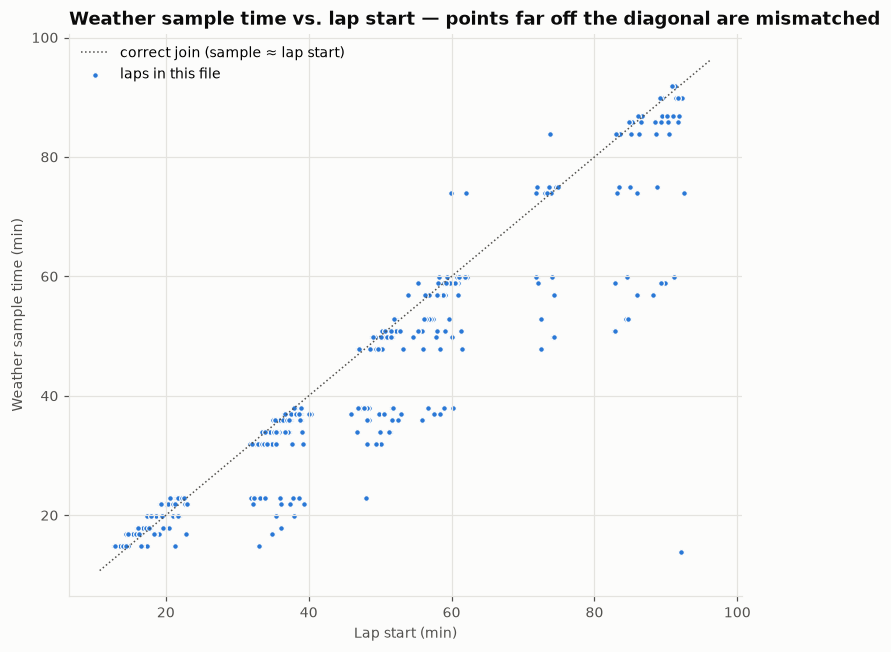

In [28]:
fig, ax = plt.subplots(figsize=(7, 6))
lim = [df.lST.min() / 60 - 2, df.sesT.max() / 60 + 2]
ax.plot(lim, lim, color=INK2, lw=1, ls=":", label="correct join (sample ≈ lap start)")
ax.scatter(df.lST / 60, df.wT / 60, s=14, color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.8,
           label="laps in this file")
ax.set_xlabel("Lap start (min)")
ax.set_ylabel("Weather sample time (min)")
ax.set_title("Weather sample time vs. lap start — points far off the diagonal are mismatched")
ax.legend(loc="upper left")
plt.tight_layout()

Don't use the `w*` columns for analysis. Use `weather.json` from the same upstream session and join on
session time (e.g. `pd.merge_asof` on `lST`). The values themselves are stable anyway: air 20.3–20.6 °C,
no rain.

## 13. Summary

**Session**
- Russell took pole with 1:18.518 and set all three session-best sectors on that lap; Antonelli +0.293 made it a Mercedes 1-2.
- Two red flags: Q1 at ~23 min (all cars on track, Verstappen's run ended there) and Q3 during the first runs.
- Bortoleto made the Q2 top 10 but has no Q3 laps; Stroll and Sainz are not in the file.

**Before analysing this file**
1. Filter to push laps — `time` includes out-laps.
2. Don't use the per-lap weather columns; re-join `weather.json` on session time.
3. `delR` lap numbers are off by one; trust `del` and `lap`.
4. Two sector values are carried over from the previous lap (VER L2 `s1`, BOR L14 `s3`).
5. `pb` is reliable; `pos` is always empty in qualifying.